# Задание 8. Сравнение алгоритмов классификации SMS

Подбор параметров идёт кросс-валидацией на обучающей выборке, порог выбирается на валидационной. Тестовая выборка используется один раз в конце.

In [1]:
# Настройка путей. Работает локально и в Google Colab.
import sys
import zipfile
from pathlib import Path

if "google.colab" in sys.modules and not Path("ml").exists():
    # В Colab загрузите архив проекта sms_guard.zip (см. README).
    from google.colab import files
    uploaded = files.upload()
    zipfile.ZipFile(next(iter(uploaded))).extractall(".")

ROOT = Path.cwd() if (Path.cwd() / "ml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print("Корень проекта:", ROOT.name)

Корень проекта: AIproject


In [2]:
import json
import os
import time
from datetime import date

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score, confusion_matrix, f1_score, fbeta_score,
    make_scorer, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from ml.data.split_sms import load_datasets
from ml.features import HAND_FEATURE_NAMES, build_sms_pipeline

os.environ["PYTHONPATH"] = str(ROOT)  # процессы GridSearchCV тоже должны видеть пакет ml
data = load_datasets()
train, val, test = data["train"], data["val"], data["test"]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
F2 = make_scorer(fbeta_score, beta=2)
MIN_PRECISION = 0.90  # раздел 3.4: Precision SMS-модели не ниже 0,90, это строже, чем 0,85 из задания 8
print({name: len(part) for name, part in data.items()})

{'train': 3594, 'val': 770, 'test': 771}


## Подбор гиперпараметров (StratifiedKFold, 5 фолдов, метрика F2)

In [3]:
CANDIDATES = {
    "Naive Bayes": (MultinomialNB(), {"clf__alpha": [0.01, 0.1, 0.5, 1.0]}),
    "Logistic Regression": (
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42),
        {"clf__C": [1, 10, 100]},
    ),
    "Linear SVM": (
        CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=42), cv=3),
        {"clf__estimator__C": [0.1, 1, 10]},
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", random_state=42, n_jobs=1),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 60]},
    ),
}
searches = {}
for name, (classifier, grid) in CANDIDATES.items():
    started = time.perf_counter()
    search = GridSearchCV(build_sms_pipeline(classifier), grid, scoring=F2, cv=CV, n_jobs=4)
    search.fit(train["text_raw"], train["label"])
    searches[name] = search
    print(f"{name}: {search.best_params_}, F2 (CV) = {search.best_score_:.4f}, {time.perf_counter() - started:.0f} с")

Naive Bayes: {'clf__alpha': 0.1}, F2 (CV) = 0.9571, 13 с


Logistic Regression: {'clf__C': 100}, F2 (CV) = 0.9455, 10 с


Linear SVM: {'clf__estimator__C': 1}, F2 (CV) = 0.9433, 11 с


Random Forest: {'clf__max_depth': None, 'clf__n_estimators': 400}, F2 (CV) = 0.9011, 38 с


## Сравнение на валидационной выборке

In [4]:
def evaluate(model, frame, threshold=0.5):
    started = time.perf_counter()
    proba = model.predict_proba(frame["text_raw"])[:, 1]
    per_sms_ms = (time.perf_counter() - started) / len(frame) * 1000
    pred = (proba >= threshold).astype(int)
    y = frame["label"]
    return proba, {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "F2": fbeta_score(y, pred, beta=2),
        "ROC-AUC": roc_auc_score(y, proba),
        "PR-AUC": average_precision_score(y, proba),
        "Мс на 1 SMS": per_sms_ms,
    }

rows, val_proba = {}, {}
for name, search in searches.items():
    model = search.best_estimator_
    started = time.perf_counter()
    model.fit(train["text_raw"], train["label"])
    fit_seconds = time.perf_counter() - started
    val_proba[name], metrics = evaluate(model, val)
    rows[name] = {**metrics, "Обучение, с": fit_seconds}
comparison = pd.DataFrame(rows).T
comparison.round(4)

,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,Мс на 1 SMS,"Обучение, с"
Naive Bayes,0.9896,0.9468,0.9674,0.9570,0.9632,0.9954,0.9833,0.2823,1.4679
Logistic Regression,0.9883,0.9663,0.9348,0.9503,0.9409,0.9957,0.9850,0.2881,1.6394
Linear SVM,0.9896,0.9884,0.9239,0.9551,0.9361,0.9958,0.9858,0.2930,1.8101
Random Forest,0.9779,0.9870,0.8261,0.8994,0.8539,0.9956,0.9845,0.4326,6.9013


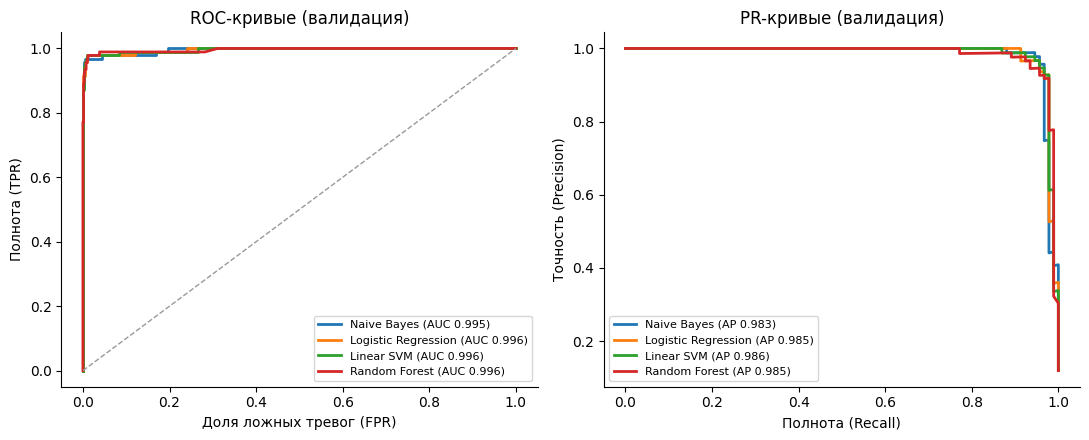

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, proba in val_proba.items():
    fpr, tpr, _ = roc_curve(val["label"], proba)
    precision, recall, _ = precision_recall_curve(val["label"], proba)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC {roc_auc_score(val['label'], proba):.3f})")
    axes[1].plot(recall, precision, lw=2, label=f"{name} (AP {average_precision_score(val['label'], proba):.3f})")
axes[0].plot([0, 1], [0, 1], color="#999999", lw=1, ls="--")
axes[0].set(title="ROC-кривые (валидация)", xlabel="Доля ложных тревог (FPR)", ylabel="Полнота (TPR)")
axes[1].set(title="PR-кривые (валидация)", xlabel="Полнота (Recall)", ylabel="Точность (Precision)")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "sms_roc_pr.png", dpi=130)
plt.show()

## Сравнение вариантов признаков (Logistic Regression с лучшим C)

In [6]:
best_c = searches["Logistic Regression"].best_params_["clf__C"]
VARIANTS = {
    "Только слова": {"use_char": False, "use_hand": False},
    "Слова + символы": {"use_char": True, "use_hand": False},
    "Слова + символы + ручные": {"use_char": True, "use_hand": True},
    "То же без стоп-слов": {"use_char": True, "use_hand": True, "remove_stop": True},
}
variant_rows = {}
for name, options in VARIANTS.items():
    model = build_sms_pipeline(LogisticRegression(C=best_c, class_weight="balanced", max_iter=2000, random_state=42), **options)
    model.fit(train["text_raw"], train["label"])
    variant_rows[name] = evaluate(model, val)[1]
pd.DataFrame(variant_rows).T.round(4)

,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,Мс на 1 SMS
Только слова,0.9883,0.9770,0.9239,0.9497,0.9341,0.9970,0.9870,0.0667
Слова + символы,0.9896,0.9773,0.9348,0.9556,0.9430,0.9967,0.9862,0.2041
Слова + символы + ручные,0.9883,0.9663,0.9348,0.9503,0.9409,0.9957,0.9850,0.2852
То же без стоп-слов,0.9896,0.9667,0.9457,0.9560,0.9498,0.9946,0.9827,0.2879


## Подбор порога на валидации

Для каждой модели берём минимальный порог, при котором Precision ≥ 0,85: так Recall максимален. Итоговая модель выбирается по F2 при этом пороге.

In [7]:
def pick_threshold(y, proba):
    precision, recall, thresholds = precision_recall_curve(y, proba)
    precision, recall = precision[:-1], recall[:-1]
    f2 = 5 * precision * recall / np.maximum(4 * precision + recall, 1e-9)
    f2[precision < MIN_PRECISION] = -1
    return float(thresholds[int(np.argmax(f2))])

threshold_rows = {}
for name, proba in val_proba.items():
    t = pick_threshold(val["label"], proba)
    pred = (proba >= t).astype(int)
    threshold_rows[name] = {
        "Порог": t,
        "Precision": precision_score(val["label"], pred),
        "Recall": recall_score(val["label"], pred),
        "F2": fbeta_score(val["label"], pred, beta=2),
    }
thresholds = pd.DataFrame(threshold_rows).T
best_name = thresholds[thresholds["Precision"] >= MIN_PRECISION]["F2"].idxmax()
print("Выбрана модель:", best_name)
thresholds.round(4)

Выбрана модель: Logistic Regression


,Порог,Precision,Recall,F2
Naive Bayes,0.7409,0.9570,0.9674,0.9653
Logistic Regression,0.0782,0.9278,0.9783,0.9677
Linear SVM,0.1099,0.9278,0.9783,0.9677
Random Forest,0.1925,0.9184,0.9783,0.9657


In [8]:
THRESHOLD = round(threshold_rows[best_name]["Порог"], 4)
final = searches[best_name].best_estimator_
test_proba, test_metrics = evaluate(final, test, THRESHOLD)
print(f"Порог {THRESHOLD}")
pd.Series(test_metrics).round(4).to_frame("Тест, класс spam")

Порог 0.0782


,"Тест, класс spam"
Accuracy,0.9844
Precision,0.9263
Recall,0.9462
F1,0.9362
F2,0.9422
ROC-AUC,0.9925
PR-AUC,0.9811
Мс на 1 SMS,0.2905


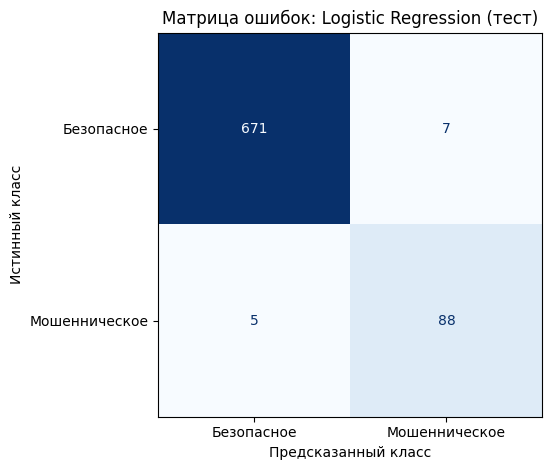

FN: 5, FP: 7

Пропуски (FN):
  P=0.00 | How come it takes so little time for a child who is afraid of the dark to become a teenager who wants to stay out all night?
  P=0.00 | For sale - arsenal dartboard. Good condition but no doubles or trebles!
  P=0.03 | Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all the adult parties...
  P=0.03 | dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?
  P=0.05 | 0A$NETWORKS allow companies to bill for SMS, so they are responsible for their "suppliers", just as a shop has to give a guarantee on what they sell. B. G.

Ложные тревоги (FP):
  P=0.58 | I lost 4 pounds since my doc visit last week woot woot! Now I'm gonna celebrate by stuffing my face!
  P=0.36 | Glad to see your reply.
  P=0.18 | what is your account number?
  P=0.14 | Can you plz tell me the ans. BSLVYL sent via fullonsms.com
  P=0.

In [9]:
test_pred = (test_proba >= THRESHOLD).astype(int)
display = ConfusionMatrixDisplay(confusion_matrix(test["label"], test_pred), display_labels=["Безопасное", "Мошенническое"])
display.plot(cmap="Blues", colorbar=False, values_format="d")
display.ax_.set(title=f"Матрица ошибок: {best_name} (тест)", xlabel="Предсказанный класс", ylabel="Истинный класс")
display.figure_.tight_layout()
display.figure_.savefig(FIGURES / "sms_final_confusion_matrix.png", dpi=130)
plt.show()

errors = test.assign(proba=test_proba, pred=test_pred)
fn = errors[(errors["label"] == 1) & (errors["pred"] == 0)].sort_values("proba")
fp = errors[(errors["label"] == 0) & (errors["pred"] == 1)].sort_values("proba", ascending=False)
print(f"FN: {len(fn)}, FP: {len(fp)}")
for title, part in [("Пропуски (FN)", fn), ("Ложные тревоги (FP)", fp)]:
    print(f"\n{title}:")
    for row in part.head(5).itertuples():
        print(f"  P={row.proba:.2f} | {row.text_raw}")

## Переобучение на train + val и сохранение

In [10]:
train_val = pd.concat([train, val])
final.fit(train_val["text_raw"], train_val["label"])
ARTIFACTS = ROOT / "ml" / "artifacts"
joblib.dump(final, ARTIFACTS / "sms_model.joblib", compress=3)
meta = {
    "version": "1.0.0",
    "algorithm": best_name,
    "params": {k: str(v) for k, v in searches[best_name].best_params_.items()},
    "features": ["word_tfidf_1_2", "char_wb_tfidf_3_5"] + HAND_FEATURE_NAMES,
    "threshold": THRESHOLD,
    "metrics_test": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "trained_on": "train+val",
    "train_size": len(train_val),
    "trained_at": date.today().isoformat(),
}
(ARTIFACTS / "sms_model_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
meta

{'version': '1.0.0',
 'algorithm': 'Logistic Regression',
 'params': {'clf__C': '100'},
 'features': ['word_tfidf_1_2',
  'char_wb_tfidf_3_5',
  'length',
  'upper_ratio',
  'exclamation_count',
  'has_url',
  'has_money',
  'has_phone',
  'rule_group_count'],
 'threshold': 0.0782,
 'metrics_test': {'Accuracy': 0.9844,
  'Precision': 0.9263,
  'Recall': 0.9462,
  'F1': 0.9362,
  'F2': 0.9422,
  'ROC-AUC': 0.9925,
  'PR-AUC': 0.9811,
  'Мс на 1 SMS': 0.2905},
 'trained_on': 'train+val',
 'train_size': 4364,
 'trained_at': '2026-11-13'}

## Проверка на собственном русско-казахском наборе

In [11]:
custom = pd.read_csv(ROOT / "data" / "raw" / "custom_ru_kk.csv", encoding="utf-8")
custom["y"] = (custom["label"] == "fraud").astype(int)
custom["pred"] = (final.predict_proba(custom["text"])[:, 1] >= THRESHOLD).astype(int)
lang_rows = {}
for lang, part in custom.groupby("lang"):
    lang_rows[lang] = {
        "Записей": len(part),
        "Recall": recall_score(part["y"], part["pred"], zero_division=0),
        "Precision": precision_score(part["y"], part["pred"], zero_division=0),
        "Доля ложных тревог": part.loc[part["y"] == 0, "pred"].mean(),
    }
pd.DataFrame(lang_rows).T.round(3)

,Записей,Recall,Precision,Доля ложных тревог
kk,50.0,0.80,0.667,0.4
ru,100.0,0.86,0.683,0.4
